# Privacy-Preserving Training of a PIN-Code Digit Recogniser
**Responsible and Safe AI (AIML4001) — External Practical, Set D**

In [13]:
%pip install -q torch torchvision opacus matplotlib numpy reportlab

## 0. Setup, configuration and data

In [26]:
import json, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from opacus import PrivacyEngine
warnings.filterwarnings("ignore")

SEED = 42
DELTA = 1e-5
MAX_GRAD_NORM = 1.0
BATCH_SIZE = 256
EPOCHS = 3
SUBSET_SIZE = 20_000
LR = 0.1
FIXED_NOISE = 1.1
TARGET_EPSILONS = [10.0, 5.0, 1.0]
DEVICE = torch.device("cpu")
torch.manual_seed(SEED); np.random.seed(SEED)

In [27]:
# MNIST -> normalised tensors; fixed random 20,000-image training subset
tr = datasets.MNIST("./data", train=True, download=True)
te = datasets.MNIST("./data", train=False, download=True)
norm = lambda x: ((x.float() / 255.0) - 0.1307) / 0.3081

g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(tr), generator=g)[:SUBSET_SIZE]
train_set = TensorDataset(norm(tr.data[idx]).unsqueeze(1), tr.targets[idx])
test_set  = TensorDataset(norm(te.data).unsqueeze(1), te.targets)

test_loader       = DataLoader(test_set,  batch_size=1000, shuffle=False)
eval_train_loader = DataLoader(train_set, batch_size=1000, shuffle=False)
make_train_loader = lambda: DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
print("train subset:", len(train_set), "| test:", len(test_set))

train subset: 20000 | test: 10000


## 1. Model (GroupNorm, not BatchNorm) and helper functions

In [28]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1);  self.gn1 = nn.GroupNorm(4, 16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1); self.gn2 = nn.GroupNorm(8, 32)
        self.fc1 = nn.Linear(32 * 7 * 7, 64);         self.fc2 = nn.Linear(64, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.gn1(self.conv1(x))), 2)   # 14x14
        x = F.max_pool2d(F.relu(self.gn2(self.conv2(x))), 2)   # 7x7
        return self.fc2(F.relu(self.fc1(x.flatten(1))))

def new_model_and_opt():
    torch.manual_seed(SEED)
    model = CNN().to(DEVICE)
    return model, torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9)

def train_epoch(model, loader, opt):
    model.train()
    for x, y in loader:
        opt.zero_grad()
        F.cross_entropy(model(x.to(DEVICE)), y.to(DEVICE)).backward()
        opt.step()

@torch.no_grad()
def accuracy(model, loader):
    model.eval(); correct = total = 0
    for x, y in loader:
        correct += (model(x.to(DEVICE)).argmax(1).cpu() == y).sum().item(); total += y.numel()
    return 100.0 * correct / total

@torch.no_grad()
def mean_confidence(model, loader):
    model.eval()
    return torch.cat([F.softmax(model(x.to(DEVICE)), 1).max(1).values for x, _ in loader]).mean().item()

## Task 1 — Non-private baseline

In [30]:
base_model, base_opt = new_model_and_opt()
base_loader = make_train_loader()
for ep in range(EPOCHS):
    train_epoch(base_model, base_loader, base_opt)
base_acc = accuracy(base_model, test_loader)
print(f"Baseline (no DP) : test accuracy {base_acc:.1f} %")

Baseline (no DP) : test accuracy 97.0 %


## Task 2 — DP training with `make_private_with_epsilon` (ε = 10, 5, 1)

In [18]:
dp_results, dp_models = {}, {}
for eps in TARGET_EPSILONS:
    model, opt = new_model_and_opt()
    pe = PrivacyEngine(accountant="rdp")
    model, opt, loader = pe.make_private_with_epsilon(
        module=model, optimizer=opt, data_loader=make_train_loader(),
        target_epsilon=eps, target_delta=DELTA, epochs=EPOCHS, max_grad_norm=MAX_GRAD_NORM)
    for ep in range(EPOCHS):
        train_epoch(model, loader, opt)
    dp_models[eps] = model
    dp_results[eps] = dict(acc=accuracy(model, test_loader),
                           eps_spent=pe.get_epsilon(DELTA), sigma=opt.noise_multiplier)
    print(f"target eps={eps:>4}: acc={dp_results[eps]['acc']:.1f} %  eps_spent={dp_results[eps]['eps_spent']:.2f}  sigma={opt.noise_multiplier:.3f}")

target eps=10.0: acc=95.5 %  eps_spent=9.99  sigma=0.521
target eps= 5.0: acc=95.3 %  eps_spent=5.00  sigma=0.662
target eps= 1.0: acc=94.0 %  eps_spent=0.99  sigma=1.235


## Task 3 — Fixed `noise_multiplier = 1.1`, ε after every epoch

In [19]:
fmodel, fopt = new_model_and_opt()
fpe = PrivacyEngine(accountant="rdp")
fmodel, fopt, floader = fpe.make_private(
    module=fmodel, optimizer=fopt, data_loader=make_train_loader(),
    noise_multiplier=FIXED_NOISE, max_grad_norm=MAX_GRAD_NORM)
eps_per_epoch = []
for ep in range(EPOCHS):
    train_epoch(fmodel, floader, fopt)
    eps_per_epoch.append(fpe.get_epsilon(DELTA))
    print(f"epoch {ep+1}: epsilon spent = {eps_per_epoch[-1]:.2f}")
print(f"(test accuracy of this model: {accuracy(fmodel, test_loader):.1f} %)")

epoch 1: epsilon spent = 1.04
epoch 2: epsilon spent = 1.17
epoch 3: epsilon spent = 1.28
(test accuracy of this model: 94.5 %)


## Task 4 — Membership-inference check (mean max-softmax confidence)

In [20]:
membership = {}
for name, model in [("Baseline", base_model), ("DP (eps=1)", dp_models[1.0])]:
    trc, tec = mean_confidence(model, eval_train_loader), mean_confidence(model, test_loader)
    membership[name] = dict(train=trc, test=tec, gap=trc - tec)
print(f"{'MODEL':<12}{'TRAIN':>8}{'TEST':>8}{'GAP':>8}")
for n, r in membership.items():
    print(f"{n:<12}{r['train']:>8.3f}{r['test']:>8.3f}{r['gap']:>8.3f}")

MODEL          TRAIN    TEST     GAP
Baseline       0.971   0.971   0.001
DP (eps=1)     0.967   0.969  -0.001


## Task 5 — Plots: accuracy vs ε and ε vs epoch

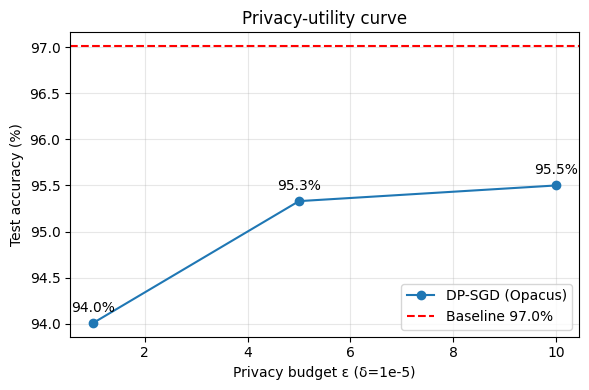

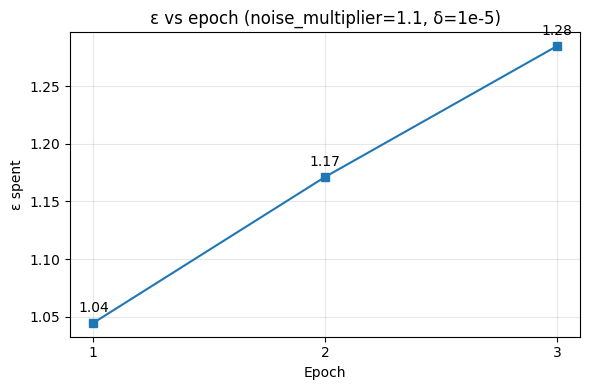

In [21]:
eps_sorted = sorted(TARGET_EPSILONS)
accs = [dp_results[e]["acc"] for e in eps_sorted]
plt.figure(figsize=(6, 4))
plt.plot(eps_sorted, accs, "o-", label="DP-SGD (Opacus)")
plt.axhline(base_acc, color="r", ls="--", label=f"Baseline {base_acc:.1f}%")
for e, a in zip(eps_sorted, accs):
    plt.annotate(f"{a:.1f}%", (e, a), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xlabel("Privacy budget ε (δ=1e-5)"); plt.ylabel("Test accuracy (%)")
plt.title("Privacy-utility curve"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), eps_per_epoch, "s-")
for i, e in enumerate(eps_per_epoch, 1):
    plt.annotate(f"{e:.2f}", (i, e), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xticks(range(1, EPOCHS + 1)); plt.xlabel("Epoch"); plt.ylabel("ε spent")
plt.title(f"ε vs epoch (noise_multiplier={FIXED_NOISE}, δ=1e-5)"); plt.grid(alpha=.3); plt.tight_layout()
plt.show()

## Task 6 — Results tables and ε recommendation

In [22]:
TOL = 5.0
rec_eps = next((e for e in sorted(TARGET_EPSILONS) if base_acc - dp_results[e]["acc"] <= TOL), max(TARGET_EPSILONS))

print("=== Accuracy at Different Privacy Budgets ===")
print(f"Baseline (no DP) : test accuracy {base_acc:.1f} %")
print(f"{'TARGET_EPS':>10} {'DELTA':>7} {'CLIP(C)':>8} {'EPOCHS':>7} {'TEST_ACC':>9} {'EPS_SPENT':>10}")
print("-" * 60)
for e in TARGET_EPSILONS:
    r = dp_results[e]
    print(f"{e:>10.1f} {DELTA:>7.0e} {MAX_GRAD_NORM:>8.1f} {EPOCHS:>7d} {r['acc']:>8.1f}% {r['eps_spent']:>10.2f}")
print("-" * 60)
print(f"Accuracy cost of strongest privacy (eps = 1) : {dp_results[1.0]['acc'] - base_acc:+.1f} %")

print(f"\n=== Privacy Accounting and Membership Check ===")
print(f"FIXED noise_multiplier = {FIXED_NOISE}")
print(f"{'EPOCH':>5} {'EPSILON_SPENT':>14}"); print("-" * 21)
for i, e in enumerate(eps_per_epoch, 1):
    print(f"{i:>5} {e:>14.2f}")
print("-" * 21)
print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print(f"{'MODEL':<12}{'TRAIN':>8}{'TEST':>8}{'GAP':>8}"); print("-" * 36)
for n, r in membership.items():
    print(f"{n:<12}{r['train']:>8.3f}{r['test']:>8.3f}{r['gap']:>8.3f}")
print("-" * 36)
print(f"Recommended eps : {rec_eps:g} ({dp_results[rec_eps]['acc'] - base_acc:+.1f} % accuracy vs baseline)")

=== Part A: Accuracy at Different Privacy Budgets ===
Baseline (no DP) : test accuracy 97.0 %
TARGET_EPS   DELTA  CLIP(C)  EPOCHS  TEST_ACC  EPS_SPENT
------------------------------------------------------------
      10.0   1e-05      1.0       3     95.5%       9.99
       5.0   1e-05      1.0       3     95.3%       5.00
       1.0   1e-05      1.0       3     94.0%       0.99
------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -3.0 %
Plot saved : accuracy_vs_epsilon.png

=== Part B: Privacy Accounting and Membership Check ===
FIXED noise_multiplier = 1.1
EPOCH  EPSILON_SPENT
---------------------
    1           1.04
    2           1.17
    3           1.28
---------------------
MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL          TRAIN    TEST     GAP
------------------------------------
Baseline       0.971   0.971   0.001
DP (eps=1)     0.967   0.969  -0.001
------------------------------------
Recommended eps : 1